# Card et al. 2024: exploring the source data

<img src="assets/experiment_illustrattion.png" alt="Brain-to-text experiment overview" width="760">

Brain-to-text speech neuroprosthesis (BrainGate2 participant **T15**, ALS / severe dysarthria). This notebook reads the **raw Dryad source** directly: per-session HDF5 neural features + phoneme/sentence labels and the online-decoding metrics pickle.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.card_2024 import study, utils
from neuralshed.datasets.utils import dataset_dir

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("card_2024") / "data"
s = study.Card2024Brain2Text(path=root)

s.download()

2026-10-15 12:09:26 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/card_2024/data/Card2024Brain2Text.


2026-10-15 12:09:34 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/card_2024/data/Card2024Brain2Text (skipped 0 non-owned items).


## Sessions and trial counts

One `SessionRef` per session folder. Trials are split into `train`, `val` and `test` files.

In [2]:
sessions = utils.list_sessions(s.path)
print(f"{len(sessions)} sessions, {sessions[0].date} → {sessions[-1].date}")

summary = pd.DataFrame(utils.session_summary(s.path))
by_split = summary.groupby("split").n_trials.sum().reindex(utils.SPLITS)
print("trials by split:", by_split.to_dict())
print("grand total    :", int(by_split.sum()))

counts = (summary.pivot_table(index="session", columns="split", values="n_trials",
                              aggfunc="sum", fill_value=0)
                 .reindex(columns=list(utils.SPLITS), fill_value=0))
counts["total"] = counts.sum(axis=1)
counts.head()

45 sessions, 2023-08-11 → 2025-04-13


trials by split: {'train': 8072, 'val': 1426, 'test': 1450}
grand total    : 10948


split,train,val,test,total
session,,,,
t15.2023.08.11,288,0,0,288
t15.2023.08.13,348,35,35,418
t15.2023.08.18,197,49,50,296
t15.2023.08.20,278,48,49,375
t15.2023.08.25,88,25,25,138


## Open one session and read a trial

In [3]:
ref = next(r for r in sessions if r.session == "t15.2023.08.13")
print("session:", ref.session, "| date:", ref.date, "| splits:", ref.splits)

first = utils.list_trials(ref, "train")[0]
trial = utils.read_trial(ref, "train", first.block, first.trial)
feat = trial["input_features"]
print("input_features:", feat.shape, feat.dtype, "(n_time_steps, 512)")
print("duration: %.2f s @ %d Hz" % (feat.shape[0] / utils.FS_NEURAL, utils.FS_NEURAL))
trial["attrs"]

session: t15.2023.08.13 | date: 2023-08-13 | splits: ('train', 'val', 'test')


input_features: (1023, 512) float32 (n_time_steps, 512)
duration: 20.46 s @ 50 Hz


{'block_num': np.int64(1),
 'n_time_steps': np.int64(1023),
 'sentence_label': 'Which is most unfortunate because we all lose out.',
 'seq_len': np.int64(42),
 'session': 't15.2023.08.13',
 'trial_num': np.int64(0)}

### Phoneme sequence and transcription

Labels exist on `train`/`val` only (`test` is held out for the Brain-to-Text '25 challenge).

In [4]:
seq_len = int(trial["attrs"]["seq_len"])
print("sentence_label:", repr(trial["attrs"]["sentence_label"]))
print("transcription :", repr(utils.decode_transcription(trial["transcription"])))
print("phonemes      :", utils.decode_phonemes(trial["seq_class_ids"], seq_len))

sentence_label: 'Which is most unfortunate because we all lose out.'
transcription : 'Which is most unfortunate because we all lose out.'
phonemes      : W IH CH | IH Z | M OW S T | AH N F AO R CH AH N AH T | B IH K AO Z | W IY | AO L | L UW Z | AW T |


### Neural feature layout

512 columns = 256 threshold crossings (0-255) + 256 spike-band power (256-511). Within each block the four arrays repeat in `ARRAY_ORDER` (64 channels each).

In [5]:
layout = utils.feature_channel_layout()
layout

{'threshold_crossings': (0, 256),
 'spike_band_power': (256, 512),
 'arrays': ('ventral 6v', 'area 4', '55b', 'dorsal 6v'),
 'channels_per_array': 64,
 'bin_size_ms': 20,
 'rate_hz': 50}

### Heatmap of `input_features` for one trial

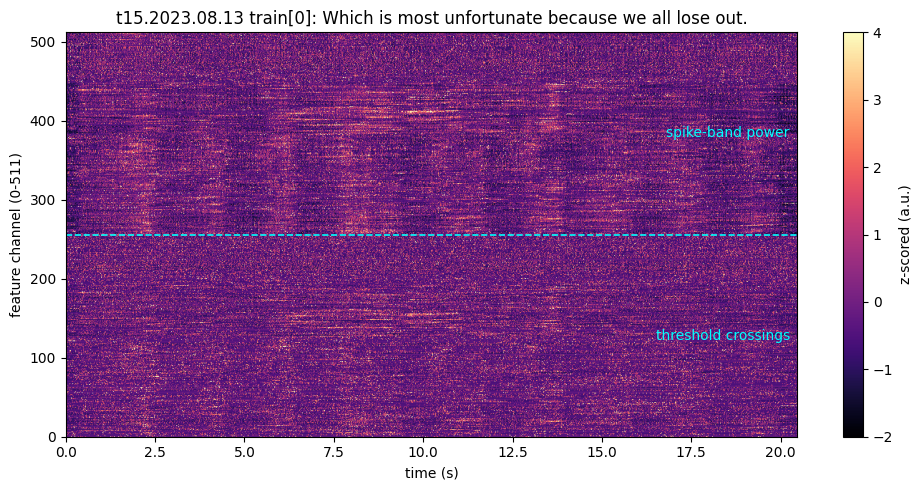

In [6]:
tc0, tc1 = layout["threshold_crossings"]
sbp0, sbp1 = layout["spike_band_power"]
dur = feat.shape[0] * utils.NEURAL_BIN_SIZE_MS / 1000

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(feat.T, aspect="auto", origin="lower", cmap="magma",
               extent=[0, dur, 0, utils.N_FEATURES], vmin=-2, vmax=4)
ax.axhline(tc1, color="cyan", lw=1.2, ls="--")
ax.text(dur * 0.99, (tc0 + tc1) / 2, "threshold crossings", color="cyan", ha="right", va="center")
ax.text(dur * 0.99, (sbp0 + sbp1) / 2, "spike-band power", color="cyan", ha="right", va="center")
ax.set(xlabel="time (s)", ylabel="feature channel (0-511)",
       title=f"{ref.session} train[0]: {trial['attrs']['sentence_label']}")
fig.colorbar(im, ax=ax, label="z-scored (a.u.)")
plt.tight_layout(); plt.show()

## Notes / scope

- **Copy task only.** Conversation-mode data (`t15_personalUse.pkl`) is out of scope.
- `test` trials carry only `input_features`. Their labels are held out for the Brain-to-Text '25 challenge.
- Neural features are z-scored within session (dimensionless). Columns 0-255 are threshold crossings, 256-511 spike-band power, four arrays each (`ventral 6v, area 4, 55b, dorsal 6v`).